# Laboratorio 2B: elegir el modelo

*Agentes de IA (aplicado) · Sesión 2 · Bloque 2.2 · Especialización en Inteligencia Artificial, UNAL Manizales*

El equipo de FotoNube recibe muchos reportes de errores cada día. Quiere un agente que los clasifique: qué tipo de problema es y qué tan urgente. ¿Con qué modelo? El más barato puede fallar más. El más grande cuesta cuarenta veces más por token. No hay un mejor modelo en general: hay un mejor modelo para tu tarea. En este laboratorio lo eliges con datos.

**Conceptos clave:**
- **Criterio de éxito:** los campos de la respuesta que deben coincidir con los esperados. Lo fijas antes de probar.
- **Tasa de éxito:** el porcentaje de casos bien resueltos.
- **Costo por caso:** el costo total entre el número de casos.
- **Costo por acierto:** el costo total entre los casos bien resueltos.
- **Latencia:** los segundos que tarda cada respuesta.
- **pass^3:** cada caso se repite tres veces. pass^3 es la proporción de casos que aciertan en los tres intentos, de 0 a 1.
- **Tratamiento de los datos:** lo que hace el proveedor con lo que le envías.

<details>
<summary><b>Repaso: lo que este laboratorio toma del 2A y del bloque 2.2</b> (clic para abrir)</summary>

- **LangChain** es la biblioteca de Python con la que el curso llama a los modelos. `init_chat_model` crea un modelo con su nombre y su proveedor.
- **Una llamada** lleva un mensaje de sistema, con las instrucciones fijas, y un mensaje de usuario, con el caso.
- **`usage_metadata`** trae los tokens de entrada y de salida. Con ellos se calcula el costo.
- **Un criterio determinista** da siempre el mismo resultado con la misma respuesta.
- **La tabla de resultados** tiene las mismas columnas en todo el curso. La sección 4.3 las explica.
- **Los tokens de razonamiento** se cobran como salida, aunque no veas su texto.
- **La ventana de contexto** es el número máximo de tokens que el modelo lee en una llamada.
- **La fecha de corte** es el final de los datos de entrenamiento de un modelo.
- **La capa 1 del proyecto** es la primera entrega de tu grupo: elegir el modelo de su agente con casos propios.
- **El caso guía** es el ejemplo de caso bien escrito de la capa 1, del bloque 2.1.
</details>

**En este laboratorio vas a:**
- fijar el criterio de éxito antes de probar;
- correr los mismos reportes en dos o tres modelos, con el mismo código;
- probar la llamada, el contenido y la consistencia de cada modelo;
- comparar la tasa de éxito, el costo por acierto, la latencia y pass^3;
- elegir un modelo con cuatro criterios, y recomendar uno en casa.

**Resultados de aprendizaje:**
- **RA1:** elegir un modelo según su calidad, su costo y el tratamiento de los datos;
- **RA7:** probar el funcionamiento y la robustez de cada etapa, y estimar su desempeño y su costo.

**Tiempo y entrega.** Son 60 minutos en clase y unas 1.5 horas en casa. En casa haces las secciones 7 a 11, unos 70 minutos, y terminas lo que no alcances en clase. Entregas este notebook ejecutado y guardado con sus salidas, al inicio de la semana siguiente.

## Cómo usar este notebook

- **Ábrelo en VS Code.** Abre la carpeta del laboratorio con «File > Open Folder» y luego abre este archivo.
- **Elige el kernel.** Arriba a la derecha, en «Select Kernel», elige el entorno virtual del curso.
- **Ejecuta en orden,** con Shift+Enter. Cada celda usa lo que hicieron las anteriores. Si reinicias el kernel, vuelve a ejecutar desde el principio.
- **Edita solo las celdas con ✏️:** los ejercicios, la configuración y tus análisis.
- **Si algo falla, lee el mensaje:** dice qué revisar. Si el error sigue, reinicia el kernel y ejecuta todo de nuevo. También puedes usar el modo grabado de la sección 1.
- **Guarda con las salidas,** con Ctrl+S (Cmd+S en Mac). El docente califica sin volver a ejecutar.

<details>
<summary><b>¿No puedes instalar VS Code? Usa Google Colab como respaldo</b> (clic para abrir)</summary>

Colab sirve solo en modo grabado.
1. En Colab, abre este notebook con «Archivo > Subir notebook».
2. En el panel «Archivos», sube el archivo `lab_2B_elegir_modelo.zip`: el mismo .zip del laboratorio que descargaste.
3. Ejecuta la primera celda de la sección 1: descomprime el archivo y entra a su carpeta.

El archivo `LEEME.md` de la carpeta explica los pasos con más detalle.
</details>

## Contenido

* [Datos de la entrega](#0)
* [1 - Preparar el entorno](#1) · en clase, 5 min
* [2 - La tarea y el criterio de éxito](#2) · en clase, 10 min
    * [2.1 - Los reportes de FotoNube](#2-1)
    * [2.2 - Las dos instrucciones](#2-2)
    * [2.3 - Ejercicio 1: el criterio de éxito](#2-3)
* [3 - Los modelos](#3) · en clase, 8 min
    * [3.1 - Cómo elegir un modelo](#3-1)
    * [3.2 - Ejercicio 2: la instrucción y los modelos](#3-2)
    * [3.3 - El mismo código, distintos modelos](#3-3)
* [4 - Las pruebas](#4) · en clase, 17 min
    * [4.1 - Ejercicio 3: tus dos reportes](#4-1)
    * [4.2 - La etapa de la llamada](#4-2)
    * [4.3 - El contenido y la consistencia](#4-3)
* [5 - La comparación](#5) · en clase, 10 min
* [6 - Ejercicio 4: la decisión](#6) · en clase, 8 min
* [7 - Para casa: la otra instrucción y el otro criterio](#7) · para casa, 20 min
* [8 - Para casa: tu recomendación](#8) · para casa, 30 min
* [9 - Entregable y calificación](#9) · para casa, 5 min
* [10 - Comprobación de la entrega](#10) · para casa, 5 min
* [11 - Tu proyecto: la capa 1](#11) · para casa, 10 min
* [Conclusión](#conclusion)
* [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para abrir)</summary>

VS Code muestra los títulos del notebook en el panel «Esquema» («Outline» en inglés). Lo encuentras en la barra lateral del Explorador, abajo. Haz clic en un título para saltar a esa sección. Si un enlace de esta tabla no funciona en tu versión de VS Code, usa el panel.
</details>

<a id='0'></a>
## Datos de la entrega

Escribe tu nombre, o los de la pareja si el docente lo permite. Estos datos se quedan en el notebook: nunca se envían a un modelo. El modo, los modelos y la fecha se agregan solos.

* ✏️ Escribe tu nombre en la celda siguiente y ejecútala.

In [ ]:
# ✏️ Datos de la entrega: escribe tu nombre entre las comillas
datos_entrega = {
    "nombres": "...",           # por ejemplo, "Ana Pérez" o "Ana Pérez y Luis Gómez"
    "modalidad": "individual",  # "individual" o "pareja", según defina el docente
}

<a id='1'></a>
## 1 - Preparar el entorno

*En clase · 5 minutos*

El arranque es el mismo del Laboratorio 2A. La celda siguiente revisa la versión de Python, instala los paquetes que falten y busca los archivos del laboratorio. En Colab, antes descomprime el archivo .zip.

* Ejecuta la siguiente celda para comprobar el entorno.

In [ ]:
# Comprueba la versión de Python, los paquetes del curso y los archivos del laboratorio
import importlib.util
import subprocess
import sys
from pathlib import Path

# En Colab: si subiste el .zip del laboratorio, lo descomprime y entra a su carpeta
if "google.colab" in sys.modules and not Path("datos").exists():
    import os, zipfile
    for archivo_zip in Path("/content").glob("lab_2B*.zip"):
        zipfile.ZipFile(archivo_zip).extractall("/content")
        os.chdir("/content/lab_2B_elegir_modelo")

print(f"Python {sys.version.split()[0]}")
if sys.version_info < (3, 11):
    print("❌ Este laboratorio necesita Python 3.11 o posterior. Elige el kernel del entorno del curso.")

# Instala en el kernel solo los paquetes que faltan, con las versiones del curso
paquetes = {"langchain": "langchain", "langchain_anthropic": "langchain-anthropic",
            "langchain_google_genai": "langchain-google-genai", "pandas": "pandas",
            "matplotlib": "matplotlib", "dotenv": "python-dotenv"}
versiones_curso = {}
if Path("requirements.txt").exists():
    for linea in Path("requirements.txt").read_text(encoding="utf-8").splitlines():
        if "==" in linea:
            versiones_curso[linea.split("==")[0].strip()] = linea.strip()
faltan = [versiones_curso.get(pip, pip) for modulo, pip in paquetes.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalo lo que falta:", ", ".join(faltan))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=False)
    print("Listo. Reinicia el kernel y vuelve a ejecutar desde el principio.")
else:
    print("✅ Los paquetes del curso están instalados.")

# Revisa los archivos del laboratorio
for ruta in ["curso_agentes", "datos/reportes_2B.json", "grabaciones"]:
    print(("✅ " if Path(ruta).exists() else "❌ falta ") + ruta)

Si ves una ❌, sigue su indicación. Si falta un archivo, abre la carpeta completa del laboratorio, no solo el notebook.

<a id='1-2'></a>
**El modo.** Como en el 2A, el notebook corre en modo grabado, sin clave, o en vivo, con la clave del curso. Con `MODO = "auto"`, usa el modo en vivo si encuentra una clave que sirve. Aquí hay dos claves posibles: `ANTHROPIC_API_KEY` y `GOOGLE_API_KEY`. Un modelo sin su clave va en modo grabado, y el notebook lo avisa.

> **Nota:** la clave vive en el archivo `.env`. Nunca la escribas en una celda: el notebook se entrega con todo lo que contiene.

* ✏️ Si quieres, cambia el modo o los límites. Luego ejecuta la siguiente celda.

In [ ]:
# ✏️ Elige el modo. Con "auto", el notebook usa el modo en vivo solo si tu clave sirve
MODO = "auto"               # "auto", "grabado" o "en_vivo"
LIMITE_LLAMADAS = 250       # en vivo, el máximo de llamadas de esta corrida
LIMITE_TOKENS = 300_000     # en vivo, el máximo de tokens de esta corrida

import pandas as pd
import curso_agentes as ca

config = ca.configurar(modo=MODO, max_llamadas=LIMITE_LLAMADAS, max_tokens=LIMITE_TOKENS, varios_modelos=True)
ca.mostrar_ficha_entrega(datos_entrega, config, modelos="los que elijas en la sección 3.2")

<a id='2'></a>
## 2 - La tarea y el criterio de éxito

*En clase · 10 minutos*

<a id='2-1'></a>
### 2.1 - Los reportes de FotoNube

**FotoNube** es una app de fotos ficticia, creada para el curso. Es la misma del registro de cambios del Laboratorio 2A. Su equipo quiere clasificar cada reporte de error con una categoría y una prioridad:

| Categoría | Qué significa |
| :--- | :--- |
| fallo de la app | La app se cierra, se congela o una función no hace lo que debe |
| rendimiento | La app funciona, pero va lenta o gasta mucha batería, memoria o datos |
| interfaz | Textos, colores, botones o pantallas que se ven mal |
| cuenta y acceso | Problemas para entrar, registrarse o recuperar la cuenta |
| solicitud de función | Una idea o un pedido de algo que la app no tiene |

La prioridad sigue estas reglas:

| Prioridad | Cuándo |
| :--- | :--- |
| alta | La app se cierra o se congela, se pierden fotos o cambios, o falla el acceso a la cuenta |
| media | Una función falla o la app va lenta, pero la persona puede seguir usándola |
| baja | Detalles visuales, textos o sugerencias |

Si un reporte trae varios problemas, se clasifica el más grave. El **caso guía** es el ejemplo de caso bien escrito de la capa 1 de tu proyecto: «La app se cierra al subir una foto en Android 15». Es un fallo de la app con prioridad alta.

* Ejecuta la siguiente celda para ver los doce reportes base, con su respuesta esperada.

In [ ]:
# Carga los reportes del laboratorio y muestra los doce de la lista base
reportes = ca.cargar_reportes()
ca.mostrar_reportes(reportes["base"])

Seis reportes son **normales**: prueban el funcionamiento. Los otros seis prueban la robustez. Tres son **de borde**: caen en el límite de una regla. Tres son **ambiguos o mal escritos**. Todos son ficticios y no traen datos personales.

<a id='2-2'></a>
### 2.2 - Las dos instrucciones

La instrucción es el mensaje de sistema: le dice al modelo qué hacer y cómo responder. El laboratorio trae dos. Las dos definen las cinco categorías y piden el mismo formato. Solo la segunda escribe las reglas de prioridad. Las respuestas esperadas siguen esas reglas en los dos casos: la pregunta es si el modelo las acierta sin que se las digas.

**Desglose del experimento**

| | Instrucción básica | Instrucción con reglas |
| :--- | :--- | :--- |
| **Qué trae** | Las categorías y el formato | Lo mismo, más las reglas de prioridad |
| **Qué debería pasar** | El modelo acierta la categoría casi siempre | También acierta más prioridades |
| **Cómo puede fallar** | Adivina la prioridad, o se deja llevar por el tono urgente | Aplica mal una regla en un caso de borde |

* Ejecuta la siguiente celda para leer las dos instrucciones completas.

In [ ]:
# Muestra las dos instrucciones, tal como llegan al modelo
for nombre, texto in reportes["instrucciones"].items():
    print(f"===== Instrucción {ca.INSTRUCCIONES[nombre]} =====\n{texto}\n")

<a id='2-3'></a>
### 2.3 - Ejercicio 1: el criterio de éxito

El criterio de éxito se fija **antes** de probar. Si lo eliges después de ver los resultados, puedes acomodarlo al modelo que te gustó.

**Qué se pide.** Elige qué campos deben coincidir para que un caso cuente como acierto:
- `"categoria"`: basta con la categoría. Sirve si el agente solo envía cada reporte al equipo correcto;
- `"categoria_y_prioridad"`: deben coincidir las dos. Sirve si el agente también decide qué se atiende primero.

**Por qué.** El criterio depende del uso. El mismo modelo puede ganar con un criterio y perder con el otro.

**Cómo saber si quedó bien.** La celda de revisión dice qué campos deben coincidir.

> **Nota:** una respuesta que no cumple el formato «Categoría: … | Prioridad: …» cuenta como fallo, con su razón. La sesión 3 resuelve esto con salidas estructuradas.

* ✏️ Escribe tu criterio en la celda siguiente y ejecútala.

In [ ]:
# ✏️ Ejercicio 1: elige el criterio de éxito, antes de probar
CRITERIO = ...   # "categoria" o "categoria_y_prioridad"

**✏️ Por qué elegiste ese criterio.** En una o dos oraciones: ¿qué haría el agente de FotoNube con la clasificación? ¿Por qué ese uso pide tu criterio?

*Escribe aquí tu respuesta.*

La celda siguiente revisa tu criterio y lo prueba con tres respuestas escritas a mano, sin llamar a ningún modelo.

* Ejecuta la siguiente celda para revisar tu criterio.

In [ ]:
# Revisa el criterio y lo prueba con tres respuestas escritas a mano
criterio_usado = ca.revisar_criterio(CRITERIO)
ejemplos = ["Categoría: fallo de la app | Prioridad: alta",
            "Categoría: fallo de la app | Prioridad: media",
            "Fallo de la app, con prioridad alta."]
for texto in ejemplos:
    pasa, razon, _, _ = ca.criterio_clasificacion(texto, "fallo de la app", "alta", criterio_usado)
    print(f"{'pasa ' if pasa else 'falla'} · {texto}" + ("" if pasa else f"  ({razon})"))

La tercera respuesta tiene la categoría correcta, pero falla: no cumple el formato. La segunda pasa o falla según tu criterio. Así ves que el criterio decide qué cuenta como acierto.

<a id='3'></a>
## 3 - Los modelos

*En clase · 8 minutos*

<a id='3-1'></a>
### 3.1 - Cómo elegir un modelo

No hay un mejor modelo en general. El bloque 2.2 propone cuatro criterios para elegir:
- **calidad en tu tarea:** con tus casos, no con un benchmark general;
- **costo y latencia:** cuánto cuesta cada acierto y cuánto tarda;
- **ventana de contexto:** cuántos tokens caben en una llamada;
- **datos y licencia:** qué hace el proveedor con tus datos y qué permite la licencia.

En este laboratorio, esos criterios se vuelven las cuatro filas de la decisión de la sección 6: la calidad en tus casos, el costo por acierto, la latencia y el tratamiento de los datos. La ventana de contexto no separa a estos modelos. Los tres leen cerca de un millón de tokens, y un reporte ocupa unos cientos.

Estos son los modelos del laboratorio, con datos de sus fuentes oficiales:

| | Claude Haiku 5.5 | Gemini 3.5 Flash-Lite | Claude Opus 5.5 |
| :--- | :--- | :--- | :--- |
| **Papel** | Obligatorio | Obligatorio | Opcional, de contraste |
| **USD por millón (entrada / salida)** | 0.10 / 0.50 | 0.30 / 2.50 | 4 / 20 |
| **Ventana de contexto** | 1 millón de tokens | 1 048 576 tokens | 1 millón de tokens |
| **Fecha de corte** | junio de 2026 | marzo de 2026 | junio de 2026 |
| **Razonamiento** | El curso lo desactiva | Mínimo por defecto | Siempre activo |

*Fuentes: [ficha de Haiku 5.5](https://platform.claude.com/docs/en/models/haiku-5-5/overview), [precios de Anthropic](https://platform.claude.com/docs/en/about-claude/pricing), [model card de Gemini 3.5 Flash-Lite](https://deepmind.google/models/model-cards/gemini-3-5-flash-lite/) y [razonamiento en Gemini](https://aistudio.google.com/docs/thinking). Consulta: 23 y 24 de noviembre de 2026.*

<details>
<summary><b>Para profundizar: por qué estos modelos</b> (clic para abrir)</summary>

- **Gemini 3.5 Flash-Lite y no 2.5 Flash-Lite.** Desde el 18 de septiembre de 2026, Google limita Gemini 2.5 Flash-Lite a quien ya lo usaba. Para proyectos nuevos recomienda 3.5 Flash-Lite.
- **El razonamiento se cobra como salida.** Gemini 3.5 Flash-Lite razona en el nivel mínimo por defecto. Su precio de salida incluye esos tokens.
- **Claude Opus 5.5 razona siempre.** Anthropic no deja desactivar su razonamiento. Por eso cada respuesta trae más tokens de salida, y cuesta más.
- **Opus 5.5 va solo en modo grabado.** Así el contraste no gasta el crédito de la clave del curso.
</details>

<a id='3-2'></a>
### 3.2 - Ejercicio 2: la instrucción y los modelos

**Qué se pide.** Elige la instrucción, básica o con reglas, y los modelos que comparas. Los dos primeros son obligatorios. Agrega Claude Opus 5.5 si quieres el contraste con un modelo grande.

**Por qué.** Configuras la comparación antes de correrla, igual que el criterio.

**Cómo saber si quedó bien.** La celda de revisión dice qué instrucción y qué modelos comparas.

* ✏️ Completa la celda siguiente y ejecútala.

In [ ]:
# ✏️ Ejercicio 2: la instrucción y los modelos que comparas
INSTRUCCION = ...   # "basica" o "con_reglas"
MODELOS = [
    "anthropic:claude-haiku-5-5",            # obligatorio
    "google_genai:gemini-3.5-flash-lite",    # obligatorio
    # "anthropic:claude-opus-5-5",           # opcional: quita el # para agregar el contraste
]

* Ejecuta la siguiente celda para revisar tu elección.

In [ ]:
# Revisa la instrucción y los modelos, y toma el mensaje de sistema que corresponde
instruccion_usada = ca.revisar_instruccion(INSTRUCCION)
modelos_usados = ca.revisar_modelos(MODELOS)
sistema = reportes["instrucciones"][instruccion_usada]

<a id='3-3'></a>
### 3.3 - El mismo código, distintos modelos

![Diagrama: la misma instrucción y el mismo reporte llegan a Claude Haiku 5.5 y a Gemini 3.5 Flash-Lite. Si lo eliges, llegan también a Claude Opus 5.5. Cada modelo se crea con init_chat_model y solo cambia su nombre. Cada respuesta se compara con el criterio de éxito. Con los resultados se calculan la tasa de éxito, los costos, la latencia y pass^3. La decisión usa cuatro criterios.](attachment:varios_modelos.png)

*Figura 1. El mismo caso en varios modelos. Diagrama propio del curso.*

Con `init_chat_model`, cambiar de modelo es cambiar un nombre. El resto del código no cambia. En modo grabado, cada modelo se reemplaza por su modelo simulado, que se usa igual.

* Ejecuta la siguiente celda para crear los modelos.
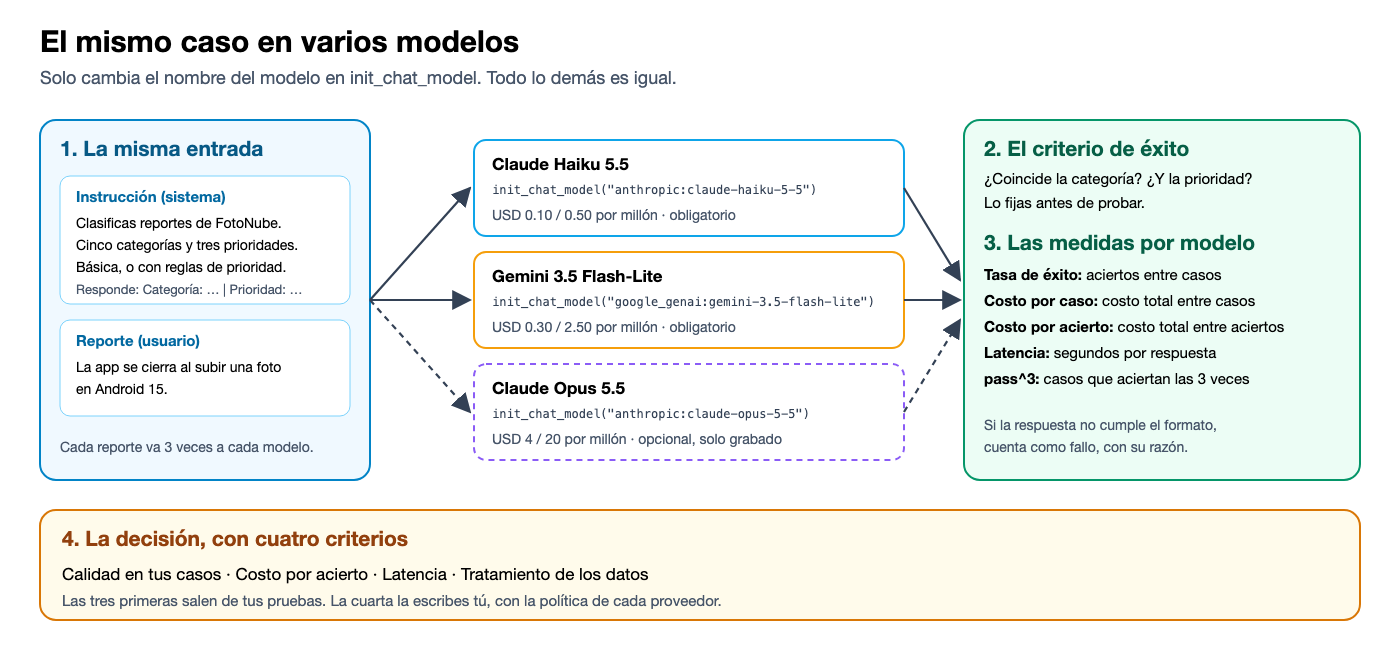

In [ ]:
# Crea cada modelo: en vivo con init_chat_model, o el modelo simulado con sus grabaciones
from langchain.chat_models import init_chat_model

modelos = {}
for nombre in modelos_usados:
    if ca.puede_ir_en_vivo(config, nombre):
        modelos[nombre] = init_chat_model(nombre, **ca.PARAMETROS[nombre])
    else:
        modelos[nombre] = ca.modelo_grabado_si_hay(config, nombre)
modelos = {nombre: m for nombre, m in modelos.items() if m is not None}
for nombre, m in modelos.items():
    print(f"Listo: {nombre} · {type(m).__name__} · {ca.PARAMETROS[nombre]}")

Cada modelo trae tres parámetros:
- `max_tokens`: el máximo de tokens de salida de cada respuesta;
- `timeout`: los segundos que el notebook espera la respuesta;
- `max_retries`: cuántas veces reintenta si el proveedor pide esperar.

Opus 5.5 tiene más tokens de salida y más tiempo de espera, porque razona siempre y tarda más. La prueba de robustez de la sección 4.2 cambia `timeout` a 0.05 segundos y `max_retries` a 0.

<a id='4'></a>
## 4 - Las pruebas

*En clase · 17 minutos*

<a id='4-1'></a>
### 4.1 - Ejercicio 3: tus dos reportes

**Qué se pide.** Agrega dos reportes del banco de reserva: uno de borde y uno ambiguo o mal escrito. Para cada uno, escribe la categoría y la prioridad que deberían salir. Usa las definiciones y las reglas de la sección 2.1, aunque hayas elegido la instrucción básica.

**Por qué.** Los casos difíciles son los que separan a un modelo de otro. Escribir su respuesta esperada te obliga a aplicar las reglas.

**Cómo saber si quedó bien.** La celda que arma la lista dice «Lista armada: 14 reportes, 2 tuyos», sin avisos ni pistas. Si dejas una pista sin resolver, tu respuesta esperada queda mal, y los modelos se califican contra ella.

* Ejecuta la siguiente celda para ver el banco de reserva.

In [ ]:
# Muestra el banco de reserva: ocho reportes con su tipo de caso, sin su respuesta esperada
ca.mostrar_banco_2B(reportes)

<details>
<summary><b>Pista</b> (clic para abrir)</summary>

- Lee primero las definiciones de las categorías. Un botón que no funciona es un fallo de la app, aunque esté en la pantalla de la cuenta.
- Si un reporte trae varios problemas, clasifica el más grave.
- **En vivo** también puedes escribir tus propios reportes. Usa un `caso_id` nuevo, como «M-01», y escribe el reporte en `entrada`.
</details>

* ✏️ Completa las dos filas de la celda siguiente y ejecútala.

In [ ]:
# ✏️ Ejercicio 3: dos reportes del banco, con la categoría y la prioridad que deberían salir
# entrada: déjala en None; el notebook copia el reporte del banco
# tipo_prueba: los casos de borde, ambiguos o mal escritos son pruebas de robustez
mis_reportes = [
    {"caso_id": ..., "etapa": "contenido", "entrada": None, "categoria": ..., "prioridad": ..., "tipo_prueba": "robustez"},  # de borde
    {"caso_id": ..., "etapa": "contenido", "entrada": None, "categoria": ..., "prioridad": ..., "tipo_prueba": "robustez"},  # ambiguo o mal escrito
]

La celda siguiente une los doce reportes base con los tuyos y revisa cada fila. Si tu respuesta esperada no coincide con las reglas, te da una pista.

* Ejecuta la siguiente celda para armar la lista de casos.

In [ ]:
# Une los reportes base con los tuyos y revisa cada fila
casos = ca.armar_casos_2B(reportes, mis_reportes, modo=config.modo)
ca.mostrar_reportes([c for c in casos if c["origen"] == "tuya"])

<a id='4-2'></a>
### 4.2 - La etapa de la llamada

La llamada tiene dos pruebas. La de funcionamiento revisa que la misma entrada llegue a todos los modelos y vuelva con texto y tokens. La corres en la sección 4.3, junto con el contenido. Aquí corres la de robustez: un modelo que no responde a tiempo.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | El caso guía, con un tiempo de espera de 0.05 segundos y sin reintentos |
| **Qué debería pasar** | La llamada se corta, y el error queda registrado en la tabla |
| **Por qué importa** | Un agente que no registra un tiempo agotado puede seguir como si el modelo hubiera respondido |

En vivo, el corte es real. En modo grabado, viene de una grabación real de un tiempo agotado.

* ✏️ Si estás en vivo y quieres, cambia el tiempo límite. Luego ejecuta la siguiente celda.

In [ ]:
# ✏️ Prueba de robustez: el mismo caso guía, con un tiempo de espera muy corto
TIEMPO_LIMITE = 0.05   # segundos
guia = next(c for c in casos if c["caso_id"] == reportes["caso_guia"])
tiempo = ca.prueba_tiempo_agotado(modelos, config, sistema, guia, limite_s=TIEMPO_LIMITE, variante=instruccion_usada)

<br>

### Análisis

La prueba pasa si el corte quedó registrado, con su tipo de error. Así el fallo es visible y nadie confunde un silencio con una respuesta. Si un modelo respondió antes del límite, la prueba también pasa: hubo texto y tokens. En las sesiones 4 y 5, un agente decide qué hacer después de un error así.

<a id='4-3'></a>
### 4.3 - El contenido y la consistencia

Ahora cada modelo recibe cada reporte tres veces, con la misma instrucción. El primer intento mide el contenido. Los tres intentos juntos miden la consistencia. En vivo, son 3 llamadas por reporte y por modelo.

* Ejecuta la siguiente celda para correr los reportes en todos los modelos.

In [ ]:
# Envía cada reporte tres veces a cada modelo y aplica el criterio de éxito
llamada, contenido, consistencia = ca.correr_comparacion(modelos, config, casos, sistema, criterio_usado,
                                                         k=3, variante=instruccion_usada)

Primero, la etapa de la llamada. Las filas con `caso_id` «todas» son su prueba de funcionamiento, una por modelo. Las filas `R-TIEMPO` son la prueba de robustez de la sección 4.2.

* Ejecuta la siguiente celda para ver la etapa de la llamada en cada modelo.

In [ ]:
# Muestra la etapa de la llamada: la misma entrada y el tiempo agotado, en cada modelo
ca.mostrar_resultados_2B(pd.concat([llamada, tiempo], ignore_index=True))

Ahora, el contenido. La primera tabla muestra qué respondió cada modelo en el primer intento: verde si acertó y rojo si falló. La segunda es la tabla de resultados completa, con las columnas de J.7. Viene plegada: ábrela para ver la razón de cada fallo, los tokens y el costo.

<details>
<summary><b>Las columnas de la tabla de resultados</b> (clic para abrir)</summary>

Son las mismas en todo el curso:
- `sesion`, `laboratorio` y `variante`: dónde se corrió la prueba y con qué instrucción;
- `forma`: `llm_directo` en toda la sesión 2. Las sesiones 4 a 7 agregan `flujo` y `agente`;
- `caso_id`, `etapa` y `tipo_prueba`: qué caso, qué etapa y qué tipo de prueba;
- `esperado`, `obtenido`, `resultado` y `razon_fallo`: qué se esperaba, qué salió, si pasa y por qué falla;
- `intento`, `modo` y `modelo`: el número de repetición, grabado o en vivo, y el modelo;
- `tokens_entrada`, `tokens_salida`, `costo_usd` y `latencia_s`: el consumo de la prueba;
- `pasos`, `llamadas_herramientas` e `intervenciones_humanas`: el comportamiento de un agente. Aquí valen 1, 0 y 0;
- `fecha`: cuándo se corrió. Las columnas `tipo_caso`, `categoria_obtenida` y `prioridad_obtenida` son propias de este laboratorio.
</details>

* Ejecuta la siguiente celda para ver el contenido, reporte por reporte.

In [ ]:
# Muestra lo que respondió cada modelo en cada reporte, y la tabla completa en un desplegable
ca.mostrar_por_caso(contenido, casos)
ca.mostrar_resultados_2B(contenido, plegada=True)

* Ejecuta la siguiente celda para ver los tres intentos de cada reporte, en cada modelo.

In [ ]:
# Muestra cada intento con ✓ o ✗: una fila por reporte y una columna por modelo
ca.mostrar_consistencia_modelos(contenido, consistencia)

<br>

### Análisis

- **En la tabla de contenido,** compara lo que respondió cada modelo con lo esperado. ¿Falló la categoría, la prioridad o el formato?
- **Mira los reportes de robustez** (de borde, ambiguos y mal escritos). Ahí suelen separarse los modelos.
- **En la cuadrícula de intentos,** una celda verde acertó las tres veces, y una roja no acertó ninguna. Una celda sin color cambió entre intentos: ese reporte no es confiable con ese modelo.

<a id='5'></a>
## 5 - La comparación

*En clase · 10 minutos*

Las medidas resumen las pruebas de cada modelo. El costo por acierto junta la calidad y el costo:

$$\text{costo por acierto} = \frac{\text{costo total de los casos}}{\text{número de casos bien resueltos}}$$

Un ejemplo: un modelo cuesta USD 0.002 por los 14 casos y acierta 10. Cada acierto le cuesta USD 0.0002. Otro modelo cuesta la mitad, pero acierta 4. Cada acierto le cuesta USD 0.00025. El barato resulta más caro por acierto.

> **Nota:** la tasa de éxito, los tokens y los costos usan solo el primer intento de cada caso. Es lo que pagarías por clasificar cada reporte una vez. Los intentos 2 y 3 sirven para pass^3, que va de 0 a 1: 0.50 quiere decir que la mitad de los casos acertó las tres veces.

* Ejecuta la siguiente celda para ver las medidas de cada modelo, en tabla y en gráficos.

In [ ]:
# Calcula las medidas de cada modelo y las muestra en una tabla y en cuatro gráficos
resumen = ca.resumen_por_modelo(contenido, consistencia)
ca.mostrar_resumen_modelos(resumen)
ca.grafico_comparacion(resumen, titulo=f"Instrucción {ca.INSTRUCCIONES[instruccion_usada]} · criterio: {ca.CRITERIOS[criterio_usado]}")

<br>

### Análisis

Lee las cuatro medidas juntas, no una por una:
- **Si un modelo acierta más y cuesta menos por acierto,** la decisión es fácil.
- **Si el más barato por token acierta menos,** compara el costo por acierto: puede salir más caro.
- **Si dos modelos aciertan igual,** decide por el costo, la latencia y el tratamiento de los datos.
- **Si pass^3 es bajo,** el modelo acierta a veces. Para un agente, esa inestabilidad es un riesgo.

Con 14 casos, una diferencia de uno o dos aciertos puede ser azar. Mira también la consistencia.

**✏️ Tu análisis (5).** En tres a cinco oraciones, con cifras de la tabla: ¿qué modelo acertó más? ¿Cuál costó menos por acierto? ¿Coinciden? Si agregaste Claude Opus 5.5, ¿su costo se justifica?

*Escribe aquí tu análisis.*

<a id='6'></a>
## 6 - Ejercicio 4: la decisión

*En clase · 8 minutos*

La decisión usa los cuatro criterios de la capa 1: la calidad en tus casos, el costo por acierto, la latencia y el tratamiento de los datos. Los tres primeros salen de tus pruebas. El cuarto depende del proveedor y del plan. Esto dice cada proveedor, según el bloque 2.2:

| Proveedor y plan | ¿Usa tus datos para mejorar sus productos? | ¿Revisión humana? | ¿Cuánto los guarda? |
| :--- | :--- | :--- | :--- |
| API de Gemini, gratuita | Sí | Sí, pueden leerlos | Los términos no fijan plazo |
| API de Gemini, pagada | No | Solo lo marcado como abuso | 55 días, para detectar abusos |
| API de Anthropic | No, salvo que lo autorices | Solo en revisiones de seguridad | Borra entradas y salidas en 30 días |

*Fuentes: [términos de la API de Gemini](https://aistudio.google.com/docs/terms) y [centro de privacidad de Anthropic](https://privacy.claude.com/en/articles/7996866-how-long-do-you-store-my-organization-s-data). Consulta: 23 de noviembre de 2026. La regla del curso no cambia: ningún dato personal real entra a un modelo.*

**¿Qué plan usa la clave del curso?** Para Gemini, depende de cómo se creó la clave: cuenta como pagada si su proyecto de Google Cloud tiene la facturación activa. Pregúntale al docente. Si no lo sabes, escribe qué pasa en cada plan.

**Qué se pide.** Escribe, para cada modelo, qué hace su proveedor con los datos de los reportes. Luego escribe tu decisión.

**Cómo saber si quedó bien.** La tabla de la decisión muestra tu texto en la fila «Tratamiento de los datos».

* ✏️ Completa la celda siguiente y ejecútala.

In [ ]:
# ✏️ Ejercicio 4: el tratamiento de los datos de cada modelo que comparaste
datos_por_modelo = {
    "claude-haiku-5-5": "...",
    "gemini-3.5-flash-lite": "...",
    "claude-opus-5-5": "...",   # solo si lo agregaste; si no, deja o borra esta línea
}

* Ejecuta la siguiente celda para armar la tabla de la decisión.

In [ ]:
# Arma la tabla de la decisión con tus resultados y tu texto sobre los datos
decision = ca.tabla_decision(resumen, datos_por_modelo)

**✏️ Tu decisión (6).** En dos o tres oraciones, con cifras: ¿qué modelo eliges para clasificar los reportes de FotoNube? ¿Qué criterio pesó más?

*Escribe aquí tu decisión.*

<a id='7'></a>
## 7 - Para casa: la otra instrucción y el otro criterio

*Para casa · unos 20 minutos*

Tu decisión depende de dos elecciones que hiciste antes de probar: la instrucción y el criterio. Aquí cambias cada una y miras si la decisión se sostiene.
- **La otra instrucción** se corre de nuevo en los mismos modelos. En vivo, son otras 3 llamadas por reporte y por modelo.
- **El otro criterio** no necesita llamadas: el notebook vuelve a calificar las mismas respuestas.

* Ejecuta la siguiente celda para correr los reportes con la otra instrucción.

In [ ]:
# Corre los mismos reportes con la otra instrucción, con tu mismo criterio
otra = "con_reglas" if instruccion_usada == "basica" else "basica"
llamada_otra, contenido_otra, consistencia_otra = ca.correr_comparacion(
    modelos, config, casos, reportes["instrucciones"][otra], criterio_usado, k=3, variante=otra)

* Ejecuta la siguiente celda para comparar las dos instrucciones y los dos criterios.

In [ ]:
# Compara las variantes: las dos instrucciones con tu criterio, y tu instrucción con el otro criterio
otro_criterio = "categoria" if criterio_usado == "categoria_y_prioridad" else "categoria_y_prioridad"
variantes = {
    f"{ca.INSTRUCCIONES[instruccion_usada]} · {ca.CRITERIOS[criterio_usado]}": resumen,
    f"{ca.INSTRUCCIONES[otra]} · {ca.CRITERIOS[criterio_usado]}": ca.resumen_por_modelo(contenido_otra, consistencia_otra),
    f"{ca.INSTRUCCIONES[instruccion_usada]} · {ca.CRITERIOS[otro_criterio]}": ca.resumen_por_modelo(
        ca.recalificar(contenido, otro_criterio), ca.recalificar(consistencia, otro_criterio)),
}
comparacion = ca.comparar_variantes(variantes)

**✏️ Tu análisis (7).** En tres a cinco oraciones: ¿cuánto cambiaron los aciertos con la otra instrucción? ¿Y con el otro criterio? ¿Tu decisión de la sección 6 se sostiene?

*Escribe aquí tu análisis.*

<a id='8'></a>
## 8 - Para casa: tu recomendación

*Para casa · unos 30 minutos*

**Qué se pide.** Escribe una recomendación de modelo para un caso de uso, en media página como máximo.
- Elige un caso de uso del mundo tech. Por ejemplo, clasificar los reportes de errores de una app.
- Recomienda un modelo con los criterios de la decisión de la sección 6. Como mínimo, explica la calidad, el costo y el tratamiento de los datos.
- Usa las cifras que mediste: la tasa de éxito, el costo por acierto y la latencia. Si tu caso de uso no es FotoNube, úsalas como referencia y di qué cambiaría.

**Por qué.** En la capa 1 de tu proyecto, tu grupo hace esta misma recomendación con sus propios casos.

**✏️ Tu recomendación.** Completa cada parte. Máximo media página.

- **Caso de uso:** *Escribe aquí el caso.*
- **Modelo recomendado:** *Escribe aquí el modelo.*
- **Calidad:** *La tasa de éxito y pass^3 que mediste, y qué casos fallaron.*
- **Costo:** *El costo por acierto, y el costo de mil casos al mes: el costo por caso por 1 000.*
- **Tratamiento de los datos:** *Qué plan del proveedor necesitas y por qué.*
- **Condición o riesgo:** *Qué tendría que pasar para cambiar de modelo.*

<a id='9'></a>
## 9 - Entregable y calificación

*Para casa · 5 minutos*

**Qué entregas.** Este notebook, ejecutado de principio a fin y guardado con sus salidas. Debe tener:
- tus datos de la entrega;
- los cuatro ejercicios resueltos, con sus tablas y sus gráficos;
- tus análisis, tu decisión y tu recomendación, en las celdas ✏️;
- la declaración de uso de asistentes de IA y la comprobación de la entrega.

**Cómo se califica.** El laboratorio vale el 2.5 % de la calificación del curso:

| Criterio | Peso | Qué mira el docente |
| :--- | :--- | :--- |
| Funciona según su criterio de éxito | 40 % | El notebook corre y las pruebas corren, sin errores |
| Las pruebas están completas y corridas | 40 % | Las pruebas de funcionamiento y de robustez, con tus reportes, en cada modelo |
| El análisis está al día | 20 % | Tus análisis, tu decisión, tu recomendación y la sección «Tu proyecto» |

**Cómo guardar con las salidas.**
1. Ejecuta todo en orden, hasta la comprobación de la sección 10.
2. Guarda con Ctrl+S (Cmd+S en Mac).
3. Cierra el notebook y vuelve a abrirlo. Si ves las tablas y los gráficos sin ejecutar nada, quedaron guardados.

> **Nota:** no uses «Clear All Outputs» antes de entregar. Esa opción borra las salidas que el docente necesita ver.

**Uso de asistentes de IA.** El curso permite usar asistentes de IA como apoyo, siempre que declares su uso.

* ✏️ Completa la declaración en la celda siguiente y ejecútala.

In [ ]:
# ✏️ Declaración de uso de asistentes de IA
declaracion_ia = {
    "usaste_asistentes": None,   # True o False, sin comillas
    "cuales_y_para_que": "...",  # por ejemplo: "Claude, para entender un mensaje de error"
}

<a id='10'></a>
## 10 - Comprobación de la entrega

*Para casa · 5 minutos*

La celda siguiente revisa que la entrega esté completa. Muestra «listo», «revisa» o «falta» en cada parte. «Revisa» quiere decir que la parte está, pero tiene algo por corregir. Orienta, no califica. Como no puede leer las celdas de texto, tus análisis los revisas tú.

* Ejecuta la siguiente celda para comprobar tu entrega.

In [ ]:
# Revisa que la entrega esté completa: muestra «listo», «revisa» o «falta» en cada parte
entrega_completa = ca.comprobar_entrega_2B(
    datos_entrega=datos_entrega, config=config, criterio=CRITERIO, instruccion=INSTRUCCION,
    modelos=modelos_usados, casos=casos, llamada=llamada, tiempo=tiempo, contenido=contenido,
    consistencia=consistencia, datos_por_modelo=datos_por_modelo, contenido_otra=contenido_otra,
    declaracion_ia=declaracion_ia,
)

<a id='11'></a>
## 11 - Tu proyecto: la capa 1

*Para casa · 10 minutos*

**Qué capa avanza.** Este laboratorio completa la capa 1 de tu proyecto: el modelo. Su resultado va en la sección 1 de la ficha del agente.

**Cómo reutilizar este notebook.** Cambia los reportes por los diez casos de tu tarea y los tres de robustez: los que tu grupo escribió después del bloque 2.1, en la sección 1 de la ficha del agente. Cambia la instrucción por la de tu tarea. Fija el criterio de éxito antes de probar, campo por campo. Luego corre los casos en dos modelos, con la clave del curso. Por ejemplo:
- si tu agente **clasifica**, compara la categoría y, si importa, la prioridad;
- si **extrae datos**, compara cada campo con el esperado;
- si **resume**, revisa los datos que no pueden faltar;
- si **responde preguntas**, prueba también las que no debería responder.

**Qué llevas a la ficha.** El modelo elegido y su razón, con los cuatro criterios. También la tabla de resultados, la consistencia y el costo por acierto. Usa datos sintéticos o anonimizados, nunca datos personales reales.

**Qué sigue.** La capa 2, en la sesión 3, agrega las instrucciones del agente y las salidas estructuradas. Con ellas, el formato deja de ser un problema.

**✏️ Tu proyecto.** Responde en dos o tres oraciones: ¿qué dos modelos vas a comparar en tu proyecto? ¿Qué criterio de éxito vas a usar, campo por campo?

*Escribe aquí tu respuesta.*

<a id='conclusion'></a>
## Conclusión

En este laboratorio fijaste un criterio de éxito antes de probar. Corriste los mismos reportes en varios modelos, con el mismo código. Mediste su calidad, su costo por acierto, su latencia y su consistencia. Viste que el modelo más barato por token no siempre es el más barato por acierto. También viste que el criterio y la instrucción cambian los resultados. Al final elegiste un modelo con cuatro criterios, incluido el tratamiento de los datos.

Con esto cierras la sesión 2 y la capa 1. La sesión 3 trabaja las instrucciones y las salidas estructuradas.

<a id='referencias'></a>
## Referencias

**Del bloque 2.2**
- OpenAI (2025, 5 de septiembre). *Why language models hallucinate*. [Original](https://openai.com/index/why-language-models-hallucinate/) · [en español](https://openai.com/es-419/index/why-language-models-hallucinate/).
- Anthropic. *Pricing*. https://platform.claude.com/docs/en/about-claude/pricing
- Anthropic. *Claude Haiku 5.5*. https://platform.claude.com/docs/en/models/haiku-5-5/overview
- Google. *Gemini Developer API pricing*. https://aistudio.google.com/docs/pricing
- Google. *Gemini thinking*. https://aistudio.google.com/docs/thinking
- Google DeepMind. *Gemini 3.5 Flash-Lite, model card*. https://deepmind.google/models/model-cards/gemini-3-5-flash-lite/
- Google. *Gemini API Additional Terms of Service*. https://aistudio.google.com/docs/terms
- Anthropic. *How long do you store my organization's data?* Centro de privacidad. https://privacy.claude.com/en/articles/7996866-how-long-do-you-store-my-organization-s-data
- Huyen, C. (2024). *AI Engineering*, capítulos 1 y 2. O'Reilly.

**De la capa de evaluación del curso (Anexo J)**
- Grace, M., Hadfield, J., Olivares, R. y De Jonghe, J. (2026, 9 de enero). *Demystifying evals for AI agents*. Anthropic. https://www.anthropic.com/engineering/demystifying-evals-for-ai-agents
- Yao, S., Shinn, N., Razavi, P. y Narasimhan, K. (2025). *τ-bench: A Benchmark for Tool-Agent-User Interaction in Real-World Domains*. ICLR 2025. https://arxiv.org/abs/2406.12045

**Documentación de las herramientas**, consultada el 24 de noviembre de 2026
- LangChain. *Models*: `init_chat_model` con distintos proveedores. https://docs.langchain.com/oss/python/langchain/models
- LangChain. *Unit testing*: los modelos simulados. https://docs.langchain.com/oss/python/langchain/test/unit-testing
- Visual Studio Code. *Jupyter Notebooks in VS Code*. https://code.visualstudio.com/docs/datascience/jupyter-notebooks